In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from pathlib import Path
from PIL import Image
from IPython.display import display

print("NeuroDrive - Dataset Exploration")
print("All libraries imported successfully!")

NeuroDrive - Dataset Exploration
All libraries imported successfully!


In [3]:
# Project directories
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_ROOT / "data" / "raw"
CSV_PATH = DATA_DIR / "driving_log.csv"
IMAGE_DIR = DATA_DIR / "IMG"

# Define column names
columns = [
    "center",
    "left",
    "right",
    "steering",
    "throttle",
    "brake",
    "speed"
]

# Load CSV without treating the first record as a header
df = pd.read_csv(
    CSV_PATH,
    header=None,
    names=columns
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (2911, 7)


,center,left,right,steering,throttle,brake,speed
0,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.0,0,0.000084
1,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.0,0,0.000105
2,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.0,0,0.000125
3,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.0,0,0.000243
4,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.0,0,0.000027


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2911 entries, 0 to 2910
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   center    2911 non-null   object 
 1   left      2911 non-null   object 
 2   right     2911 non-null   object 
 3   steering  2911 non-null   float64
 4   throttle  2911 non-null   float64
 5   brake     2911 non-null   int64  
 6   speed     2911 non-null   float64
dtypes: float64(3), int64(1), object(3)
memory usage: 159.3+ KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
steering,2911.0,-0.013346,0.511117,-1.000000,0.000000,0.00000,0.000000,1.00000
throttle,2911.0,0.329558,0.432728,0.000000,0.000000,0.00000,0.903309,1.00000
brake,2911.0,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000
speed,2911.0,19.838774,6.268498,0.000027,16.040195,20.37769,24.139310,30.50995


In [8]:
missing_values = df.isnull().sum()

print("Missing values per column:")
display(missing_values)

print("Total missing values:", missing_values.sum())

Missing values per column:


center      0
left        0
right       0
steering    0
throttle    0
brake       0
speed       0
dtype: int64

Total missing values: 0


In [9]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [10]:
def resolve_image_path(path):
    filename = str(path).replace("\\", "/").split("/")[-1]
    return IMAGE_DIR / filename


for column in ["center", "left", "right"]:
    df[f"{column}_path"] = df[column].apply(resolve_image_path)

# Check image existence
for column in ["center", "left", "right"]:
    existing = df[f"{column}_path"].apply(lambda p: p.is_file()).sum()
    missing = len(df) - existing

    print(f"{column.capitalize()} images:")
    print("Existing:", existing)
    print("Missing:", missing)
    print("-" * 30)

Center images:
Existing: 2911
Missing: 0
------------------------------
Left images:
Existing: 2911
Missing: 0
------------------------------
Right images:
Existing: 2911
Missing: 0
------------------------------


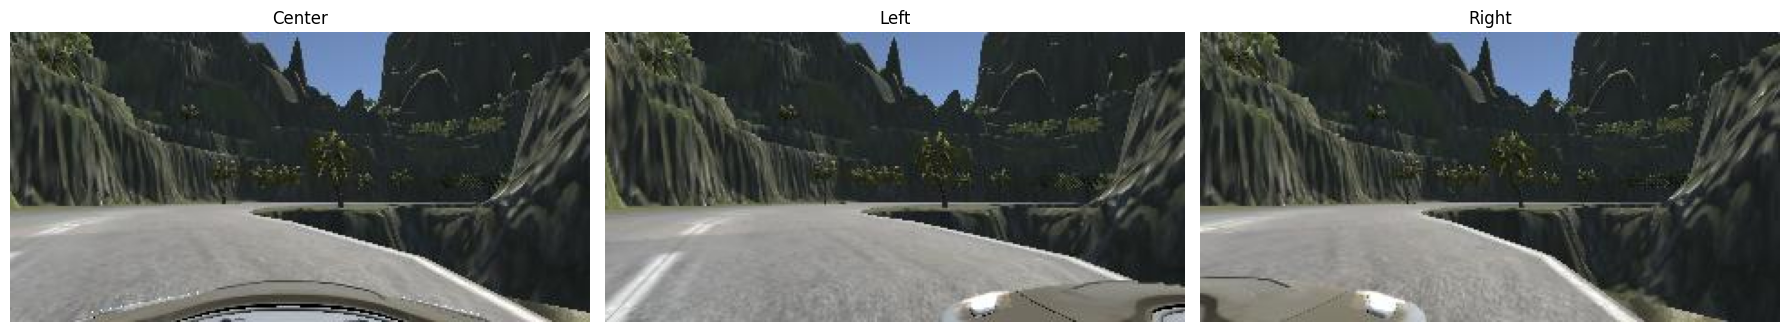

Steering angle: -0.45
Throttle: 1.0
Speed: 17.6466


In [13]:
sample = df.iloc[100]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

camera_columns = ["center_path", "left_path", "right_path"]

for ax, column in zip(axes, camera_columns):

    image = cv2.imread(str(sample[column]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(column.replace("_path", "").capitalize())
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Steering angle:", sample["steering"])
print("Throttle:", sample["throttle"])
print("Speed:", sample["speed"])

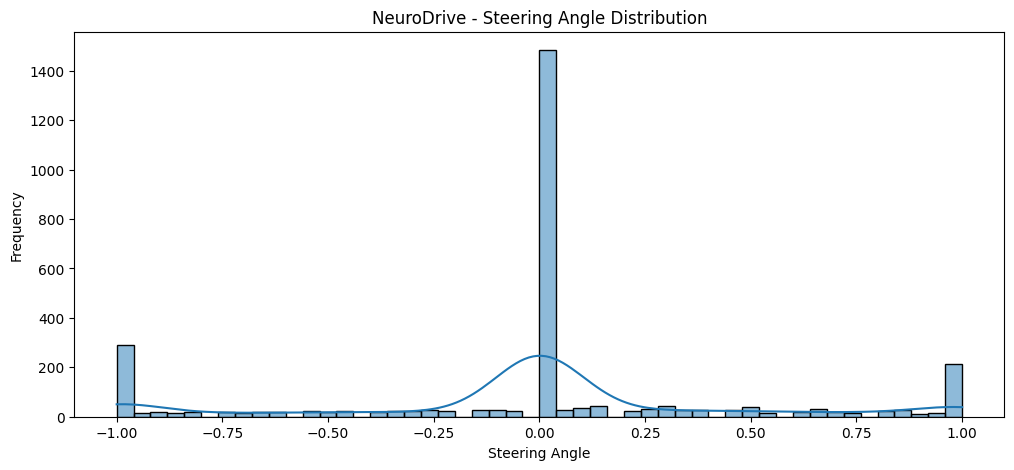

In [14]:
plt.figure(figsize=(12, 5))

sns.histplot(
    df["steering"],
    bins=50,
    kde=True
)

plt.title("NeuroDrive - Steering Angle Distribution")
plt.xlabel("Steering Angle")
plt.ylabel("Frequency")

plt.show()

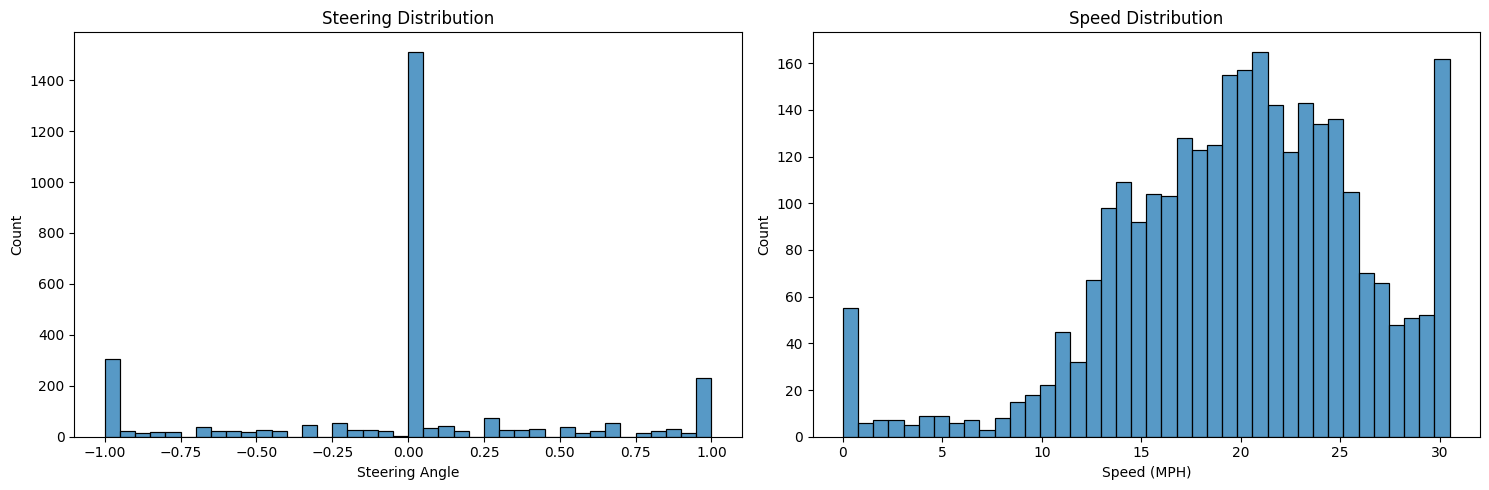

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Steering distribution
sns.histplot(
    df["steering"],
    bins=40,
    ax=axes[0]
)

axes[0].set_title("Steering Distribution")
axes[0].set_xlabel("Steering Angle")

# Speed distribution
sns.histplot(
    df["speed"],
    bins=40,
    ax=axes[1]
)

axes[1].set_title("Speed Distribution")
axes[1].set_xlabel("Speed (MPH)")

plt.tight_layout()
plt.show()

In [16]:
summary = {
    "Total driving records": len(df),
    "Total camera images": len(df) * 3,
    "Zero steering records": (df["steering"] == 0).sum(),
    "Left steering records": (df["steering"] < 0).sum(),
    "Right steering records": (df["steering"] > 0).sum(),
    "Average steering": df["steering"].mean(),
    "Minimum steering": df["steering"].min(),
    "Maximum steering": df["steering"].max(),
    "Average speed": df["speed"].mean(),
    "Maximum speed": df["speed"].max()
}

for key, value in summary.items():
    print(f"{key}: {value}")

Total driving records: 2911
Total camera images: 8733
Zero steering records: 1484
Left steering records: 703
Right steering records: 724
Average steering: -0.013345928189625555
Minimum steering: -1.0
Maximum steering: 1.0
Average speed: 19.838773890607403
Maximum speed: 30.50995
